In [208]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold


from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import QuantileTransformer

from sklearn.metrics import mean_absolute_error

from sklearn.feature_selection import mutual_info_regression


from scikeras.wrappers import KerasRegressor
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
import tensorflow as tf
from tensorflow.keras import Input

import random
from heapq import nsmallest

In [209]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [210]:
# Fix random state
random_state = 42

In [211]:
PRETTY_LABELS = {
    "U_lsr":        r"$U_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "V_lsr":        r"$V_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "W_lsr":        r"$W_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UV_lsr":       r"$UV_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UW_lsr":       r"$UW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "VW_lsr":       r"$VW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UVW_lsr":      r"$UVW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_U_lsr":    r"$|U|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_W_lsr":    r"$|W|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "P_gal":        r"$P_{\mathrm{gal}}\,[\%]$",
    "rapo":         r"$R_{\mathrm{apo}}\,[\mathrm{kpc}]$",
    "rperi":        r"$R_{\mathrm{peri}}\,[\mathrm{kpc}]$",
    "zmax":         r"$Z_{\max}\,[\mathrm{kpc}]$",
    "eccentricity": r"$e$",
    "R_mean":       r"$R_{\mathrm{mean}}\,[\mathrm{kpc}]$",
}

In [212]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

apogee = apogee[apogee.parallax > 0.]
galah = galah[(galah.parallax > 0.) ]

apogee['rel_parallax'] = apogee.parallax_error / apogee.parallax
apogee = apogee[apogee.rel_parallax < 0.1]

galah['rel_parallax'] = galah.parallax_error / galah.parallax
galah = galah[galah.rel_parallax < 0.1]


harps['rel_parallax'] = harps.parallax_error / harps.parallax
harps = harps[harps.rel_parallax < 0.1]

# Seelcting only giants
apogee = apogee[apogee.logg < 3]

# Selecting only dwarfs
galah = galah[galah.logg > 3]


apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

galah.isnull().sum() # 1 null value for P_gal
galah.dropna(inplace = True)

#harps.isnull().sum() # No null values


galah = galah[(galah.zmax < 10) ]

apogee = apogee[(apogee.zmax < 10) ]
apogee.shape


print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 45727 stars
galah contains 69449 stars
gr8 contains 1430 stars


In [213]:
def fit_trasform(X):
    #X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    #X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    #X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    X['UVW_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2 + X['W_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    #X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    #X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    #X['abs_W_lsr'] =np.abs(X['W_lsr'])
    #X['abs_U_lsr'] =np.abs(X['U_lsr'])
    #X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    #X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])
    #X.drop(columns = ['U_lsr', 'W_lsr'], inplace = True)
    #X['R_mean'] = (X['rapo'] + X['rperi'])/2
    #X.drop(columns = ['rperi', 'rapo'], inplace = True)

    return X

apogee = fit_trasform(apogee)
harps = fit_trasform(harps)

# Here we focus on getting Fe from no abundance

In [214]:
columns_for_abundances = ['U_lsr', 'V_lsr', 'W_lsr', 'P_gal', 'rapo', 'rperi', 'eccentricity', 'zmax', 'fe_h', 'o_h', 'mg_h', 'si_h', 'c_h']

apogee = apogee[columns_for_abundances]
harps = harps[columns_for_abundances]

o_features = ['U_lsr', 'V_lsr', 'W_lsr', 'P_gal', 'rapo', 'rperi', 'eccentricity', 'zmax', 'fe_h', 'o_h']
apogee_o = apogee[o_features]
harps_o = harps[o_features]
harps_o.dropna(inplace = True)

si_features = ['U_lsr', 'V_lsr', 'W_lsr', 'P_gal', 'rapo', 'rperi', 'eccentricity', 'zmax', 'fe_h', 'si_h']
apogee_si = apogee[si_features]
harps_si = harps[si_features]
harps_si.dropna(inplace = True)


/tmp/ipykernel_85126/1395065871.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  harps_o.dropna(inplace = True)
/tmp/ipykernel_85126/1395065871.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  harps_si.dropna(inplace = True)


In [215]:
PRETTY_LABELS = {
    "U_lsr":        r"$U_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "V_lsr":        r"$V_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "W_lsr":        r"$W_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UV_lsr":       r"$UV_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UW_lsr":       r"$UW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "VW_lsr":       r"$VW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UVW_lsr":      r"$UVW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_U_lsr":    r"$|U|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_W_lsr":    r"$|W|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "P_gal":        r"$P_{\mathrm{gal}}\,[\%]$",
    "rapo":         r"$R_{\mathrm{apo}}\,[\mathrm{kpc}]$",
    "rperi":        r"$R_{\mathrm{peri}}\,[\mathrm{kpc}]$",
    "zmax":         r"$Z_{\max}\,[\mathrm{kpc}]$",
    "eccentricity": r"$e$",
    "R_mean":       r"$R_{\mathrm{mean}}\,[\mathrm{kpc}]$",
    "o_h":          r"$[\mathrm{O/H}]$",
    "mg_h":         r"$[\mathrm{Mg/H}]$",
    "si_h":         r"$[\mathrm{Si/H}]$",
    "c_h":          r"$[\mathrm{C/H}]$",
}

In [216]:
class AbundancePredictor:

    def __init__(self, apogee_df, harps_df, element, features=None, random_state=42):
        """
        Parameters
        ----------
        apogee_df : pandas.DataFrame
            Training dataset (used for train/validation split and tuning).
        harps_df : pandas.DataFrame
            Independent test dataset.
        element : str
            Target abundance (e.g. 'o_h', 'mg_h', 'si_h', 'c_h').
        features : list, optional
            Input features used for prediction.
        """

        self.apogee_df = apogee_df.copy()
        self.harps_df = harps_df.copy()
        self.element = element
        self.random_state = random_state

        if features is None:
            self.features = ['U_lsr', 'V_lsr', 'W_lsr', 'P_gal', 'rapo', 'rperi', 'eccentricity', 'zmax', 'fe_h',  ]
        else:
            self.features = features

        self.model = None

    def prepare_element_data(self, dropna_harps=True):
        """
        Prepare APOGEE and HARPS dataframes for the selected element.

        Returns
        -------
        apogee_el : DataFrame
            APOGEE dataframe containing features + target element
        harps_el : DataFrame
            HARPS dataframe containing features + target element
        """

        cols = self.features + [self.element]

        self.apogee_el = self.apogee_df[cols].copy()
        self.harps_el  = self.harps_df[cols].copy()

        if dropna_harps:
            self.harps_el = self.harps_el.dropna()

        return self.apogee_el, self.harps_el

    def split_data(self, test_size=0.1):

        X = self.apogee_df[self.features]
        y = self.apogee_df[self.element]

        self.X_train, self.X_val, self.y_train, self.y_val = train_test_split(
            X, y,
            test_size=test_size,
            random_state=self.random_state
        )
        return self.X_train, self.X_val, self.y_train, self.y_val
    
    def split_X_y_features(self):

        self.X = self.apogee_df[self.features]
        self.y = self.apogee_df[self.element]
        self.X_harps = self.harps_df[self.features]
        self.y_harps = self.harps_df[self.element]

        return self.X, self.y, self.features, self.X_harps, self.y_harps

    def compute_spearman(self, df):
        corr = (
            df.corr(numeric_only=True, method="spearman")[self.element]
            .drop(self.element)
            .sort_values(key=abs, ascending=False)
        )
        return corr
    
    def plot_spearman_correlations(self, pretty_labels, savepath=None):

        corr_apogee = self.compute_spearman(self.apogee_el)
        corr_harps = self.compute_spearman(self.harps_el)

        fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=False)

        datasets = {
            "APOGEE": corr_apogee,
            "HARPS": corr_harps
        }

        axes = axes.flatten()

        for ax, (name, corr) in zip(axes, datasets.items()):

            values = corr.values
            labels = [pretty_labels.get(f, f) for f in corr.index]

            ax.barh(labels, values)
            ax.set_title(name, fontsize=12)
            ax.axvline(0, color="black", linewidth=0.8)
            ax.invert_yaxis()

        fig.supxlabel(f"Spearman correlations with [{self.element.upper().replace('_H','/H')}]", fontsize=14)
        fig.supylabel("Features", fontsize=16)

        plt.tight_layout()

        if savepath is not None:
            plt.savefig(savepath, dpi=300)

        plt.show()


    def compute_mi(self, df):
        X = df[self.features]
        y = df[self.element]
        mi = mutual_info_regression(
            X, y,
            random_state=self.random_state
        )
        mi_series = pd.Series(mi, index=X.columns).sort_values(ascending=False)
        return mi_series

    
    def plot_mutual_information(self, pretty_labels, savepath=None):

        mi_apogee = self.compute_mi(self.apogee_el)
        mi_harps  = self.compute_mi(self.harps_el)

        fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=False)

        datasets = {
            "APOGEE": mi_apogee,
            "HARPS": mi_harps
        }

        for ax, (name, mi) in zip(axes, datasets.items()):

            labels = [pretty_labels.get(f, f) for f in mi.index]

            ax.barh(labels, mi.values)
            ax.set_title(name, fontsize=12)
            ax.invert_yaxis()

        fig.supxlabel(
            f"Mutual Information with [{self.element.upper().replace('_H','/H')}]",
            fontsize=16
        )
        fig.supylabel("Features", fontsize=16)

        plt.tight_layout()

        if savepath:
            plt.savefig(savepath, dpi=300)

        plt.show()

In [217]:
def build_keras_regressor(input_dim, lr=0.001):
    model = Sequential([
        Input(shape=(input_dim,)), 
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(16, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss='mae', metrics=['mae'])
    return model



dl_model = KerasRegressor(
    model=build_keras_regressor,
    model__lr=0.007,
    epochs=20,
    batch_size=64,
    verbose=0,
    #callbacks=[tf.keras.callbacks.EarlyStopping(monitor='mae', patience=5, restore_best_weights=True)]
    validation_split=0.2,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)]
)


In [218]:
rfr = RandomForestRegressor(random_state=random_state, n_jobs=-1)
xgbr = XGBRegressor(random_state=random_state, n_jobs=-1)
lr = LinearRegression()  # no internal parallel
svr = SVR()  # no internal parallel
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1, objective="huber")
catbr = CatBoostRegressor(random_state=random_state, verbose=False, thread_count=-1)
extr = ExtraTreesRegressor(random_state=random_state, n_jobs=-1)


qt = QuantileTransformer(
    output_distribution="normal",
    n_quantiles=100,
    random_state=random_state
)

lgbr_qt = TransformedTargetRegressor(
    regressor=lgbr,
    transformer=qt
)

xgbr_qt = TransformedTargetRegressor(
    regressor=xgbr,
    transformer=qt
)

catbr_qt = TransformedTargetRegressor(
    regressor=catbr,
    transformer=qt
)



voting_r = VotingRegressor(estimators=[
    ('xgbr', xgbr),
    ('rfr', rfr),
    ('extr', extr),
    ('lgbr', lgbr),
    ('catr', catbr)
])

model_names = {
    'dl_model': dl_model,
    'xgbr': xgbr,
    'xgbr_qt': xgbr_qt,
    'rfr': rfr,
    'extr': extr,  
    'svr': svr,
    'lr': lr,
    'lgbr': lgbr,
    'lgbr_qt': lgbr_qt,
    'catr': catbr,
    'catbr_qt': catbr_qt,
    'voting_r': voting_r 
}


In [219]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
import numpy as np
import time

def model_test_CV_models(X, y, base_pred, models, k=5, random_state=42):
    """
    Perform k-fold cross-validation for multiple models.
    Returns mean and std of RMSE, MAE, and R2.
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()

        rmse_scores = []
        rmse_base_scores = []
        mae_scores = []
        r2_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            # Special handling for scikeras models
            if isinstance(model, KerasRegressor):
                model.set_params(model__input_dim=X_train.shape[1])

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            y_pred_base = base_pred.iloc[test_index]

            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))
            mae = mean_absolute_error(y_test, y_pred)
            r2 = r2_score(y_test, y_pred)

            rmse_scores.append(rmse)
            rmse_base_scores.append(rmse_base)
            mae_scores.append(mae)
            r2_scores.append(r2)

        elapsed_time = time.time() - start_time

        results[name] = {
            'mean_rmse': np.mean(rmse_scores),
            'std_rmse': np.std(rmse_scores),
            'mean_rmse_base': np.mean(rmse_base_scores),
            'mean_mae': np.mean(mae_scores),
            'mean_r2': np.mean(r2_scores),
            'time_sec': elapsed_time
        }

        print(
            f"{name} → "
            f"RMSE: {results[name]['mean_rmse']:.3f} ± {results[name]['std_rmse']:.3f} | "
            f"RMSE base: {results[name]['mean_rmse_base']:.3f} | "
            f"MAE: {results[name]['mean_mae']:.3f} | "
            f"R²: {results[name]['mean_r2']:.3f} "
            f"({elapsed_time:.2f}s)\n"
        )

    return results

In [220]:
def allinone_predictor(apogee_df, harps_df, element, features, random_state=42):
    predictor = AbundancePredictor(apogee_df, harps_df, element=element, features=features, random_state=random_state)
    apogee_el, harps_el = predictor.prepare_element_data(dropna_harps=True)
    X,y,features,X_harps, y_harps = predictor.split_X_y_features()
    X_train, X_val, y_train, y_val = predictor.split_data()
    return X_train, X_val, y_train, y_val, X,y,features, X_harps, y_harps, harps_el

X_train, X_val, y_train, y_val, X,y,features,X_harps, y_harps, harps_el = allinone_predictor(apogee, harps, element = "si_h", features = None)

In [221]:
elements = ['o_h', 'mg_h', 'si_h', 'c_h']
for el in elements:
    print (el)
    X_train, X_val, y_train, y_val, X,y,features,X_harps, y_harps, harps_el = allinone_predictor(apogee, harps, element = el, features = None)
    baseline_results = model_test_CV_models(X, y, X['fe_h'], model_names, k=5)

    for name, score in baseline_results.items():
        print(f"{name:8s} | RMSE: {score['mean_rmse']:.3f} ± {score['std_rmse']:.3f}")

o_h
Scoring model: dl_model


dl_model → RMSE: 0.065 ± 0.003 | RMSE base: 0.192 | MAE: 0.050 | R²: 0.886 (59.31s)

Scoring model: xgbr
xgbr → RMSE: 0.056 ± 0.000 | RMSE base: 0.192 | MAE: 0.040 | R²: 0.915 (1.93s)

Scoring model: xgbr_qt
xgbr_qt → RMSE: 0.057 ± 0.001 | RMSE base: 0.192 | MAE: 0.040 | R²: 0.914 (3.52s)

Scoring model: rfr
rfr → RMSE: 0.056 ± 0.000 | RMSE base: 0.192 | MAE: 0.040 | R²: 0.916 (50.84s)

Scoring model: extr
extr → RMSE: 0.057 ± 0.000 | RMSE base: 0.192 | MAE: 0.041 | R²: 0.914 (15.06s)

Scoring model: svr
svr → RMSE: 0.122 ± 0.001 | RMSE base: 0.192 | MAE: 0.096 | R²: 0.602 (130.35s)

Scoring model: lr
lr → RMSE: 0.061 ± 0.000 | RMSE base: 0.192 | MAE: 0.046 | R²: 0.901 (0.05s)

Scoring model: lgbr
lgbr → RMSE: 0.055 ± 0.000 | RMSE base: 0.192 | MAE: 0.039 | R²: 0.920 (4.56s)

Scoring model: lgbr_qt
lgbr_qt → RMSE: 0.055 ± 0.000 | RMSE base: 0.192 | MAE: 0.039 | R²: 0.919 (4.55s)

Scoring model: catr
catr → RMSE: 0.055 ± 0.001 | RMSE base: 0.192 | MAE: 0.039 | R²: 0.920 (22.25s)

Scorin

o_h
Scoring model: xgbr
xgbr → RMSE: 0.056 ± 0.000 | MAE: 0.040 | R²: 0.915 (1.60s)

Scoring model: rfr
rfr → RMSE: 0.056 ± 0.000 | MAE: 0.040 | R²: 0.916 (45.66s)

Scoring model: extr
extr → RMSE: 0.057 ± 0.000 | MAE: 0.041 | R²: 0.914 (12.67s)

Scoring model: lgbr
lgbr → RMSE: 0.055 ± 0.000 | MAE: 0.039 | R²: 0.920 (4.67s)

Scoring model: catr
catr → RMSE: 0.055 ± 0.001 | MAE: 0.039 | R²: 0.920 (21.78s)

xgbr     | RMSE: 0.056 ± 0.000
rfr      | RMSE: 0.056 ± 0.000
extr     | RMSE: 0.057 ± 0.000
lgbr     | RMSE: 0.055 ± 0.000
catr     | RMSE: 0.055 ± 0.001
mg_h
Scoring model: xgbr
xgbr → RMSE: 0.051 ± 0.000 | MAE: 0.036 | R²: 0.938 (2.37s)

Scoring model: rfr
rfr → RMSE: 0.051 ± 0.000 | MAE: 0.037 | R²: 0.937 (45.36s)

Scoring model: extr
extr → RMSE: 0.051 ± 0.000 | MAE: 0.037 | R²: 0.937 (12.51s)

Scoring model: lgbr
lgbr → RMSE: 0.049 ± 0.001 | MAE: 0.035 | R²: 0.941 (5.46s)

Scoring model: catr
catr → RMSE: 0.049 ± 0.000 | MAE: 0.035 | R²: 0.941 (21.97s)

xgbr     | RMSE: 0.051 ± 0.000
rfr      | RMSE: 0.051 ± 0.000
extr     | RMSE: 0.051 ± 0.000
lgbr     | RMSE: 0.049 ± 0.001
catr     | RMSE: 0.049 ± 0.000
si_h
Scoring model: xgbr
xgbr → RMSE: 0.038 ± 0.000 | MAE: 0.028 | R²: 0.968 (2.20s)

Scoring model: rfr
rfr → RMSE: 0.038 ± 0.000 | MAE: 0.028 | R²: 0.967 (45.52s)

Scoring model: extr
extr → RMSE: 0.038 ± 0.000 | MAE: 0.028 | R²: 0.967 (15.67s)

Scoring model: lgbr
lgbr → RMSE: 0.037 ± 0.000 | MAE: 0.027 | R²: 0.969 (6.05s)

Scoring model: catr
catr → RMSE: 0.037 ± 0.000 | MAE: 0.027 | R²: 0.969 (27.05s)

xgbr     | RMSE: 0.038 ± 0.000
rfr      | RMSE: 0.038 ± 0.000
extr     | RMSE: 0.038 ± 0.000
lgbr     | RMSE: 0.037 ± 0.000
catr     | RMSE: 0.037 ± 0.000
c_h
Scoring model: xgbr
xgbr → RMSE: 0.081 ± 0.001 | MAE: 0.060 | R²: 0.888 (3.33s)

Scoring model: rfr
rfr → RMSE: 0.081 ± 0.001 | MAE: 0.060 | R²: 0.887 (57.18s)

Scoring model: extr
extr → RMSE: 0.082 ± 0.000 | MAE: 0.061 | R²: 0.885 (15.94s)

Scoring model: lgbr
lgbr → RMSE: 0.079 ± 0.001 | MAE: 0.058 | R²: 0.893 (7.47s)

Scoring model: catr
catr → RMSE: 0.079 ± 0.001 | MAE: 0.058 | R²: 0.893 (27.17s)

xgbr     | RMSE: 0.081 ± 0.001
rfr      | RMSE: 0.081 ± 0.001
extr     | RMSE: 0.082 ± 0.000
lgbr     | RMSE: 0.079 ± 0.001
catr     | RMSE: 0.079 ± 0.001

In [222]:
from sklearn.base import clone

def individual_feature_importance(model, model_name, X, y, X_test, y_test):
    """
    Trains a model with each feature individually and compares MAE to full model.
    """
    model_full = clone(model)
    model_full.fit(X, y)

    feature_names = X.columns

    # Full prediction
    y_pred_full = model_full.predict(X_test)
    rmse_full =  np.sqrt(mean_squared_error(y_test, y_pred_full))

    # Individual feature performance
    rmse_individual = []
    for feature in feature_names:
        model_feat = clone(model)
        model_feat.fit(X[[feature]], y)
        y_pred_feat = model_feat.predict(X_test[[feature]])
        rmse_individual.append(np.sqrt(mean_squared_error(y_test, y_pred_feat))) 

    # Plot
    plt.figure(figsize=(12, 6))
    plt.bar(['Full Model'] + list(feature_names), [rmse_full] + rmse_individual, color=['gray'] + ['steelblue']*len(feature_names))
    plt.axhline(y=rmse_full, color='red', linestyle='--', label='Full Model MAE')

    plt.ylabel('Root Mean Square Error (RMSE)')
    plt.title(f'Individual Feature Importance by RMSE – {model_name}')
    plt.xticks(rotation=45, ha='right')
    plt.legend()
    plt.tight_layout()
    plt.show()
    return rmse_individual


o_h


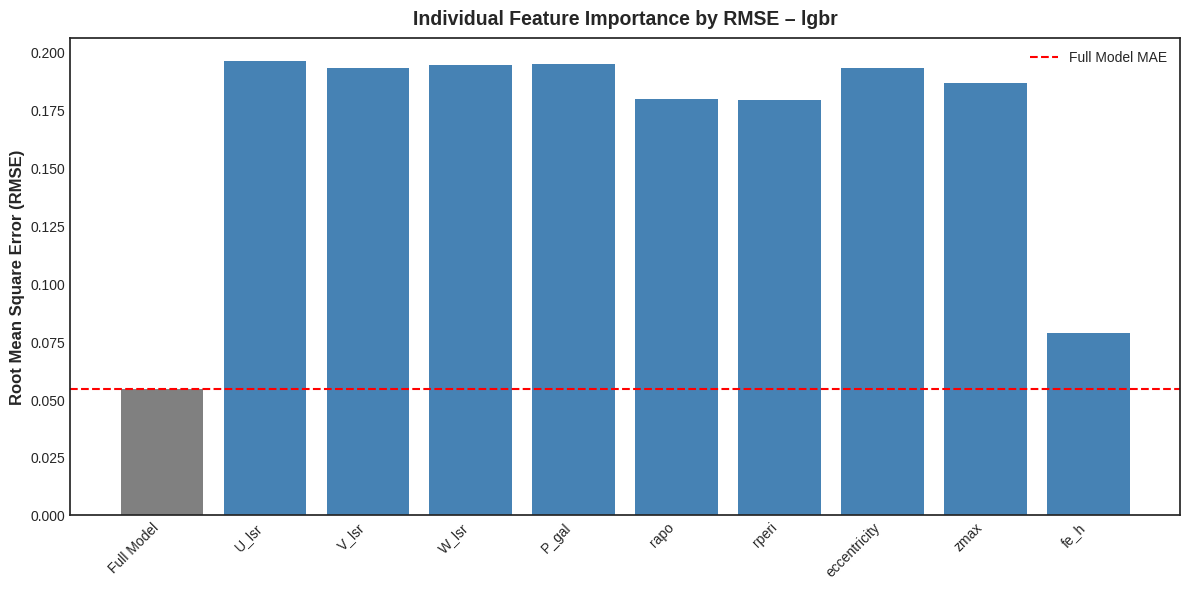

mg_h


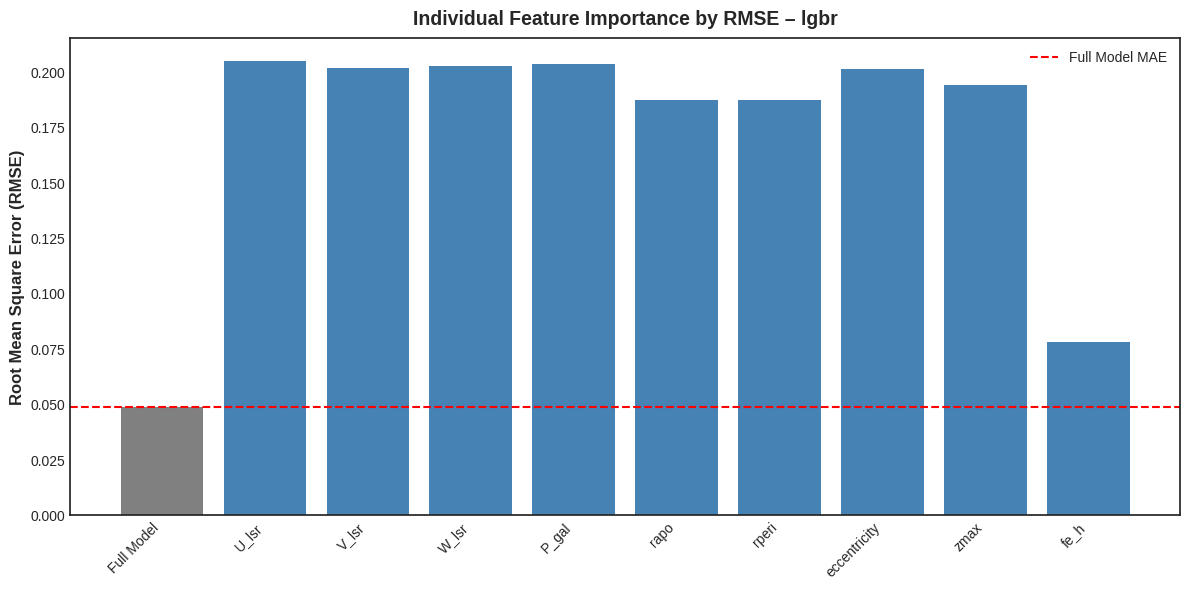

si_h


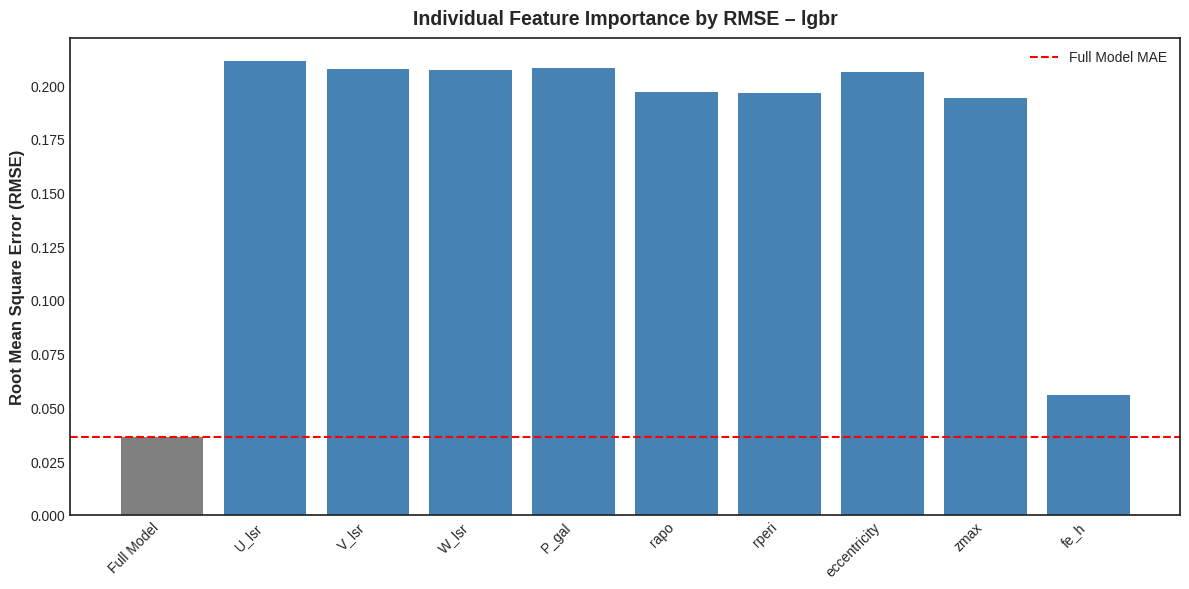

c_h


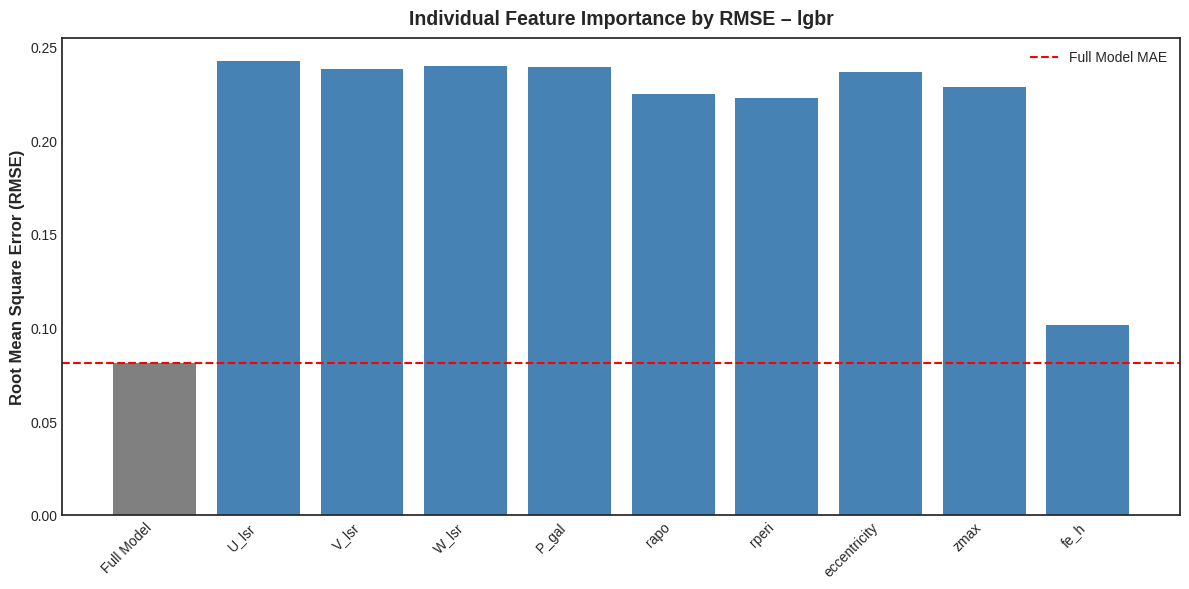

In [223]:
elements = ['o_h', 'mg_h', 'si_h', 'c_h']
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1)

model_names = {
    'lgbr': lgbr,
}
# Example for one model and one test set
best_model_name = 'lgbr'
model = model_names[best_model_name]

for el in elements:
    print (el)
    X_train, X_val, y_train, y_val, X,y,features,X_harps, y_harps, harps_el = allinone_predictor(apogee, harps, element = el, features = None)
    rmse_individual = individual_feature_importance(model, 'lgbr', X_train, y_train, X_val, y_val)


In [224]:
def evaluate_on_test_data(X_train, y_train, test_df, target, models, test_name='Test'):
    """
    Trains models on the full training set and evaluates on a test set.

    Parameters:
        X_train, y_train: Training features and target.
        test_df: DataFrame containing the test data (including the target column).
        target (str): Name of the target column in test_df.
        models: Dictionary of model_name: model_instance.
        test_name (str): Label for this test set (e.g., 'Apogee', 'HARPS').

    Returns:
        dict: model_name → test MAE and baseline MAE
    """
    X_test = test_df.drop(columns=[target])
    y_test = test_df[target]

    results = {}

    for name, model in models.items():
        print(f"Training and evaluating {name} on {test_name}")
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        mae_model = mean_absolute_error(y_test, y_pred)
        rmse_model = np.sqrt(mean_squared_error(y_test, y_pred))
        mae_baseline = mean_absolute_error(y_test, [y_test.mean()] * len(y_test))
        rmse_baseline = np.sqrt(mean_squared_error(y_test, [y_test.mean()] * len(y_test)))


        results[name] = {
            'rmse_model': rmse_model,
            'rmse_baseline': rmse_baseline
        }

        print(f"{name} | {test_name} RMSE: {rmse_model:.3f} (mean baseline: {rmse_baseline:.3f})\n")

    return results


In [225]:
# Evaluate on Apogee test
results_apogee = evaluate_on_test_data(
    X, y,
    test_df=harps_el,
    target='c_h',
    models=model_names,
    test_name='HARPS'
)


Training and evaluating lgbr on HARPS
lgbr | HARPS RMSE: 0.097 (mean baseline: 0.218)



In [226]:
def plot_residuals_vs_true(y_true, y_pred, base_pred, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs y_true, and residuals from predicting the mean.

    Parameters:
        y_true: Ground truth target values.
        y_pred: Model predictions.
        model_name: Name of the model for labeling.
        sample_name: Name of the dataset (e.g., 'Apogee' or 'HARPS').
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_mean = np.full_like(y_true, y_true.mean())

    residuals_model = y_true - y_pred
    residuals_mean = y_true - base_pred

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, residuals_model, alpha=0.6, label=f'{model_name}', s=20)
    plt.scatter(y_true, residuals_mean, alpha=0.4, label='Mean predictor', s=20, marker='x')

    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('True Value (y)')
    plt.ylabel('Residual (y_true - y_pred)')
    plt.title(f'Residuals vs True Values ({sample_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

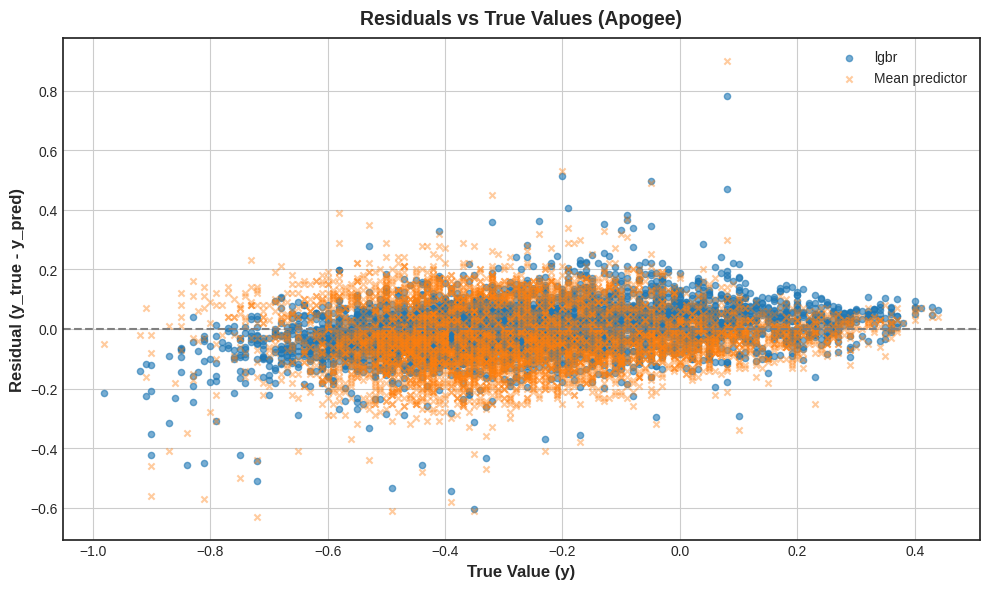

In [227]:
# Example for one model and one test set
best_model_name = 'lgbr'
model_lgbr = model_names[best_model_name]
model_lgbr.fit(X_train, y_train)

y_pred_apogee_xgbr = model_lgbr.predict(X_val)
plot_residuals_vs_true(y_val, y_pred_apogee_xgbr, X_val['fe_h'], model_name=best_model_name, sample_name='Apogee')

In [228]:
from sklearn.base import clone

def individual_feature_importance(model, model_name, X, y, X_test, y_test):
    """
    Trains a model with each feature individually and compares MAE to full model.
    """
    model_full = clone(model)
    model_full.fit(X, y)

    feature_names = X.columns

    # Full prediction
    y_pred_full = model_full.predict(X_test)
    rmse_full =  np.sqrt(mean_squared_error(y_test, y_pred_full))

    # Individual feature performance
    rmse_individual = []
    for feature in feature_names:
        model_feat = clone(model)
        model_feat.fit(X[[feature]], y)
        y_pred_feat = model_feat.predict(X_test[[feature]])
        rmse_individual.append(np.sqrt(mean_squared_error(y_test, y_pred_feat))) 

    # Plot
    plt.figure(figsize=(12, 6))
    plt.bar(['Full Model'] + list(feature_names), [rmse_full] + rmse_individual, color=['gray'] + ['steelblue']*len(feature_names))
    plt.axhline(y=rmse_full, color='red', linestyle='--', label='Full Model MAE')

    plt.ylabel('Root Mean Square Error (RMSE)')
    plt.title(f'Individual Feature Importance by RMSE – {model_name}')
    plt.xticks(rotation=45, ha='right')
    plt.legend()
    plt.tight_layout()
    plt.show()
    return rmse_individual

lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1)

model_names = {
    'lgbr': lgbr,
}
# Example for one model and one test set
best_model_name = 'lgbr'
model = model_names[best_model_name]
rmse_individual = individual_feature_importance(model, 'lgbr', X_apogee_train[best_features], y_apogee_train, X_apogee_test[best_features], y_apogee_test)

NameError: name 'best_features' is not defined

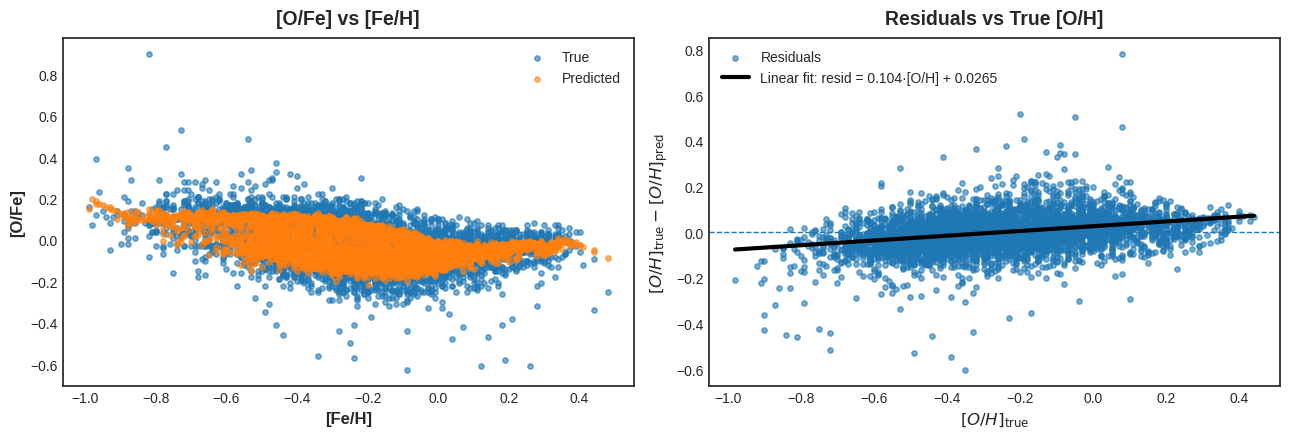

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Inputs assumed:
# X_apogee_test: DataFrame with column "fe_h" (=[Fe/H])
# y_apogee_test: Series/array with true [O/H]
# y_pred_apogee_xgbr: array with predicted [O/H]

feh = X_val["fe_h"].to_numpy()
y_true = np.asarray(y_val)
y_pred = np.asarray(y_pred_apogee_xgbr)

# Residuals: true - pred
resid = y_true - y_pred

# Left panel: [O/Fe] = [O/H] - [Fe/H]
ofe_true = y_true - feh
ofe_pred = y_pred - feh

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# -------------------------
# Left: [O/Fe] vs [Fe/H]
# -------------------------
axes[0].scatter(feh, ofe_true, s=15, alpha=0.6, label="True")
axes[0].scatter(feh, ofe_pred, s=15, alpha=0.6, label="Predicted")

axes[0].set_xlabel("[Fe/H]")
axes[0].set_ylabel("[O/Fe]")
axes[0].set_title("[O/Fe] vs [Fe/H]")
axes[0].legend()

# -------------------------
# Right: residuals vs y_true with linear fit
# -------------------------
axes[1].scatter(y_true, resid, s=15, alpha=0.6, label="Residuals")
axes[1].axhline(0, linestyle="--", linewidth=1)

# Linear fit: resid = a*y_true + b
a, b = np.polyfit(y_true, resid, 1)
xfit = np.linspace(np.nanmin(y_true), np.nanmax(y_true), 200)
yfit = a * xfit + b
axes[1].plot(xfit, yfit, linewidth=3, color = 'black', label=f"Linear fit: resid = {a:.3g}·[O/H] + {b:.3g}")

axes[1].set_xlabel(r"$[O/H]_{\rm true}$")
axes[1].set_ylabel(r"$[O/H]_{\rm true} - [O/H]_{\rm pred}$")
axes[1].set_title("Residuals vs True [O/H]")
axes[1].legend()

plt.tight_layout()
plt.show()
